<a href="https://colab.research.google.com/github/20deepak28/demand-analysis-project/blob/main/deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


**MOUNTING AT Google Drive, for importing our project**

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print(os.listdir("/content/drive"))

['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


In [ ]:
import os

root = "/content/drive/MyDrive"

for item in os.listdir(root):
    print(item)

Retail-Demand-Forecasting
Colab Notebooks


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Retail-Demand-Forecasting"

print(os.listdir(PROJECT_PATH))

['Data', 'models', 'notebooks', 'dashboard', 'README.md', 'reports']


In [ ]:
import os

FEATURE_PATH = (
    PROJECT_PATH
    + "/Data/processed/full_dataset/featured"
)

files = sorted(os.listdir(FEATURE_PATH))

print("Total files:", len(files))
print("First 5:", files[:5])

Total files: 31
First 5: ['sales_chunk_000.parquet', 'sales_chunk_001.parquet', 'sales_chunk_002.parquet', 'sales_chunk_003.parquet', 'sales_chunk_004.parquet']


### LOAD the dataset and inspect its structure

In [ ]:
import pandas as pd
from pathlib import Path

FEATURE_PATH = Path(PROJECT_PATH) / "Data/processed/full_dataset/featured"

parquet_files = sorted(FEATURE_PATH.glob("*.parquet"))

df = pd.read_parquet(parquet_files[0])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Shape: (1941000, 27)
Columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'weekday', 'month', 'year', 'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI', 'wm_yr_wk', 'sell_price', 'revenue', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'is_event']
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   

  state_id    d  sales       date    weekday  ...  wm_yr_wk  sell_price  \
0       CA  d_1      0 2011-01-29   Saturday  ...     11101         NaN   
1       CA  d_2      0 2011-01-3

### Check data types and missing values

In [ ]:
print(df[["sales", "lag_1", "lag_7", "lag_28",
          "rolling_mean_7", "rolling_mean_28"]].isnull().sum())

print("\nData types:")
print(df[["sales", "lag_1", "lag_7", "lag_28"]].dtypes)

sales                  0
lag_1               1000
lag_7               7000
lag_28             28000
rolling_mean_7      7000
rolling_mean_28    28000
dtype: int64

Data types:
sales       int16
lag_1     float64
lag_7     float64
lag_28    float64
dtype: object


In [ ]:
print("Date range:", df["date"].min(), "to", df["date"].max())

print("Unique product-store series:", df["id"].nunique())

print("\nRows per series:")
print(df.groupby("id").size().describe())

Date range: 2011-01-29 00:00:00 to 2016-05-22 00:00:00
Unique product-store series: 1000

Rows per series:
count    1000.0
mean     1941.0
std         0.0
min      1941.0
25%      1941.0
50%      1941.0
75%      1941.0
max      1941.0
dtype: float64


### Prepare the first chunk for LSTM

In [ ]:
import numpy as np
import pandas as pd

# Sort data chronologically within each product-store series
df = df.sort_values(["id", "date"]).reset_index(drop=True)

# Convert sales to float32 and apply log transformation
df["sales_log"] = np.log1p(df["sales"].astype(np.float32))

# Check
print("Shape:", df.shape)
print("\nData types:")
print(df[["sales", "sales_log"]].dtypes)

print("\nSample:")
display(df[["id", "date", "sales", "sales_log"]].head())

Shape: (1941000, 28)

Data types:
sales          int16
sales_log    float32
dtype: object

Sample:


,id,date,sales,sales_log
0,HOBBIES_1_001_CA_1_evaluation,2011-01-29,0,0.0
1,HOBBIES_1_001_CA_1_evaluation,2011-01-30,0,0.0
2,HOBBIES_1_001_CA_1_evaluation,2011-01-31,0,0.0
3,HOBBIES_1_001_CA_1_evaluation,2011-02-01,0,0.0
4,HOBBIES_1_001_CA_1_evaluation,2011-02-02,0,0.0


### Identify our LSTM feautes

In [ ]:
print("Available columns:")
print(df.columns.tolist())

print("\nSelected feature information:")
features = [
    "sales",
    "sell_price",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

print(df[features].dtypes)
print("\nMissing values:")
print(df[features].isnull().sum())

Available columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'weekday', 'month', 'year', 'event_name_1', 'event_type_1', 'snap_CA', 'snap_TX', 'snap_WI', 'wm_yr_wk', 'sell_price', 'revenue', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'is_event', 'sales_log']

Selected feature information:
sales                int16
sell_price         float32
lag_1              float64
lag_7              float64
lag_28             float64
rolling_mean_7     float64
rolling_mean_28    float64
day_of_week          int64
month                int64
is_event              int8
snap_CA              int64
snap_TX              int64
snap_WI              int64
dtype: object

Missing values:
sales                   0
sell_price         392504
lag_1                1000
lag_7                7000
lag_28              28000
rolling_mean_7       7000
rolling_mean_28     28000
day_of_week             0
month                   0
is_event      

### Investigate missing prices

In [ ]:
missing_price = df[df["sell_price"].isna()]

print("Missing price rows:", len(missing_price))

print("\nSales distribution where price is missing:")
print(missing_price["sales"].value_counts().head(10))

print("\nPositive sales with missing price:")
print((missing_price["sales"] > 0).sum())

print("\nMissing price percentage:")
print(round(len(missing_price) / len(df) * 100, 2), "%")

Missing price rows: 392504

Sales distribution where price is missing:
sales
0    392504
Name: count, dtype: int64

Positive sales with missing price:
0

Missing price percentage:
20.22 %


### This confirms that in this chunk, all missing-price observations have zero sales.

In [ ]:
# Identify missing prices
df["price_missing"] = df["sell_price"].isna().astype("int8")

# Create a separate model-ready price column
df["sell_price_filled"] = df["sell_price"].fillna(0)

print("Missing-price indicator:")
print(df["price_missing"].value_counts())

print("\nRemaining missing prices:")
print(df["sell_price_filled"].isna().sum())

print("\nPositive sales with missing price:")
print(((df["price_missing"] == 1) & (df["sales"] > 0)).sum())

Missing-price indicator:
price_missing
0    1548496
1     392504
Name: count, dtype: int64

Remaining missing prices:
0

Positive sales with missing price:
0


### SELECT LSTM input featurs

In [ ]:
FEATURES = [
    "sales_log",
    "sell_price_filled",
    "price_missing",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

TARGET = "sales_log"

print("Total input features:", len(FEATURES))
print(FEATURES)

Total input features: 14
['sales_log', 'sell_price_filled', 'price_missing', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']


### Convert features to float 32

In [ ]:
# Convert model features to memory-efficient float32
df[FEATURES] = df[FEATURES].astype(np.float32)

print(df[FEATURES].dtypes)
print("\nMissing values:")
print(df[FEATURES].isna().sum())

sales_log            float32
sell_price_filled    float32
price_missing        float32
lag_1                float32
lag_7                float32
lag_28               float32
rolling_mean_7       float32
rolling_mean_28      float32
day_of_week          float32
month                float32
is_event             float32
snap_CA              float32
snap_TX              float32
snap_WI              float32
dtype: object

Missing values:
sales_log                0
sell_price_filled        0
price_missing            0
lag_1                 1000
lag_7                 7000
lag_28               28000
rolling_mean_7        7000
rolling_mean_28      28000
day_of_week              0
month                    0
is_event                 0
snap_CA                  0
snap_TX                  0
snap_WI                  0
dtype: int64


### Check Missing Values in alll Features

In [ ]:
print("Total missing values:", df[FEATURES].isna().sum().sum())

print("\nMissing values by feature:")
print(df[FEATURES].isna().sum())

Total missing values: 71000

Missing values by feature:
sales_log                0
sell_price_filled        0
price_missing            0
lag_1                 1000
lag_7                 7000
lag_28               28000
rolling_mean_7        7000
rolling_mean_28      28000
day_of_week              0
month                    0
is_event                 0
snap_CA                  0
snap_TX                  0
snap_WI                  0
dtype: int64


### HAndle missing lag features

In [ ]:
LAG_FEATURES = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

df[LAG_FEATURES] = df[LAG_FEATURES].fillna(0)

print("Remaining missing values:", df[FEATURES].isna().sum().sum())

print("Dataset shape:", df.shape)

Remaining missing values: 0
Dataset shape: (1941000, 30)


In [ ]:
print(df[FEATURES].describe().T)

                       count      mean       std  min   25%       50%  \
sales_log          1941000.0  0.374363  0.613324  0.0  0.00  0.000000   
sell_price_filled  1941000.0  4.166167  4.402140  0.0  0.72  2.970000   
price_missing      1941000.0  0.202217  0.401569  0.0  0.00  0.000000   
lag_1              1941000.0  0.922700  2.541588  0.0  0.00  0.000000   
lag_7              1941000.0  0.919489  2.539431  0.0  0.00  0.000000   
lag_28             1941000.0  0.906791  2.531924  0.0  0.00  0.000000   
rolling_mean_7     1941000.0  0.919881  1.808067  0.0  0.00  0.285714   
rolling_mean_28    1941000.0  0.909908  1.681993  0.0  0.00  0.357143   
day_of_week        1941000.0  3.002576  2.000644  0.0  1.00  3.000000   
month              1941000.0  6.334879  3.437055  1.0  3.00  6.000000   
is_event           1941000.0  0.081401  0.273475  0.0  0.00  0.000000   
snap_CA            1941000.0  0.329727  0.465153  0.0  0.00  0.000000   
snap_TX            1941000.0  0.329727  0.465153  0

### Define training dates

In [ ]:
TRAIN_END = pd.Timestamp("2015-04-07")
VALID_START = pd.Timestamp("2015-04-08")

print("Training end:", TRAIN_END)
print("Validation start:", VALID_START)

Training end: 2015-04-07 00:00:00
Validation start: 2015-04-08 00:00:00


### Initialize Scalar

In [ ]:
from sklearn.preprocessing import StandardScaler

SCALED_FEATURES = [
    "sales_log",
    "sell_price_filled",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month"
]

scaler = StandardScaler()

print("Scaler initialized.")
print("Features to scale:", len(SCALED_FEATURES))

Scaler initialized.
Features to scale: 9


### Fit the common scaler

In [ ]:
from pathlib import Path

scaler = StandardScaler()

for i, file in enumerate(parquet_files, 1):

    temp = pd.read_parquet(
        file,
        columns=["date", "sales", "sell_price",
                 "lag_1", "lag_7", "lag_28",
                 "rolling_mean_7", "rolling_mean_28",
                 "day_of_week", "month"]
    )

    temp["date"] = pd.to_datetime(temp["date"])

    # Prepare features
    temp["sales_log"] = np.log1p(
        temp["sales"].astype(np.float32)
    )

    temp["sell_price_filled"] = temp["sell_price"].fillna(0)

    temp[SCALED_FEATURES] = (
        temp[SCALED_FEATURES].fillna(0).astype(np.float32)
    )

    # Training period only
    train_data = temp.loc[
        temp["date"] <= TRAIN_END, SCALED_FEATURES
    ]

    scaler.partial_fit(train_data)

    print(f"Processed chunk {i}/31")

print("\nCommon scaler fitted successfully!")

Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31

Common scaler fitted successfully!


### Verify scaling statistics

In [ ]:
print("Feature means:")
print(scaler.mean_)

print("\nFeature standard deviations:")
print(scaler.scale_)

print("\nNumber of features:", scaler.n_features_in_)

Feature means:
[0.36777847 3.23104287 1.08506432 1.07993556 1.06400832 1.08063139
 1.06646925 3.         6.34640523]

Feature standard deviations:
[0.66714761 3.46785279 3.93563545 3.92929639 3.91159486 3.44780093
 3.2816961  2.00163332 3.46998382]

Number of features: 9


### Save the scaler

In [ ]:
import joblib

MODEL_PATH = Path(PROJECT_PATH) / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

scaler_path = MODEL_PATH / "lstm_feature_scaler.pkl"

joblib.dump(scaler, scaler_path)

print("Scaler saved:", scaler_path)

Scaler saved: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_feature_scaler.pkl


### PRepare the sequence generator

In [ ]:
SEQ_LENGTH = 28

BINARY_FEATURES = [
    "price_missing",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

MODEL_FEATURES = SCALED_FEATURES + BINARY_FEATURES

print("Total model features:", len(MODEL_FEATURES))
print("Sequence length:", SEQ_LENGTH)

Total model features: 14
Sequence length: 28


### Prepare the first parquet chunk

In [ ]:
def prepare_chunk(file):

    temp = pd.read_parquet(file)

    temp["date"] = pd.to_datetime(temp["date"])

    # Target transformation
    temp["sales_log"] = np.log1p(
        temp["sales"].astype(np.float32)
    )

    # Missing price handling
    temp["price_missing"] = (
        temp["sell_price"].isna().astype(np.int8)
    )

    temp["sell_price_filled"] = (
        temp["sell_price"].fillna(0)
    )

    # Handle initial lag NaNs
    temp[SCALED_FEATURES] = (
        temp[SCALED_FEATURES]
        .fillna(0)
        .astype(np.float32)
    )

    # Apply common scaler
    temp[SCALED_FEATURES] = scaler.transform(
        temp[SCALED_FEATURES]
    )

    # Preserve binary features
    temp[BINARY_FEATURES] = (
        temp[BINARY_FEATURES].astype(np.float32)
    )

    return temp

In [ ]:
test_chunk = prepare_chunk(parquet_files[0])

print("Shape:", test_chunk.shape)
print("Features:", test_chunk[MODEL_FEATURES].shape)
print("Missing values:", test_chunk[MODEL_FEATURES].isna().sum().sum())

Shape: (1941000, 30)
Features: (1941000, 14)
Missing values: 0


## Genrate Multivariate sequences

In [ ]:
def create_sequences(group):
    X = group[MODEL_FEATURES].to_numpy(dtype=np.float32)
    y = group["sales_log"].to_numpy(dtype=np.float32)
    dates = group["date"].to_numpy()

    X_seq = np.lib.stride_tricks.sliding_window_view(
        X, window_shape=SEQ_LENGTH, axis=0
    ).transpose(0, 2, 1)

    # Remove final window (no next-day target)
    X_seq = X_seq[:-1]

    y_seq = y[SEQ_LENGTH:]
    target_dates = dates[SEQ_LENGTH:]

    train_mask = target_dates <= np.datetime64(TRAIN_END)
    valid_mask = target_dates >= np.datetime64(VALID_START)

    return (
        X_seq[train_mask],
        y_seq[train_mask],
        X_seq[valid_mask],
        y_seq[valid_mask]
    )

In [ ]:
first_product = test_chunk[
    test_chunk["id"] == test_chunk["id"].iloc[0]
].sort_values("date").reset_index(drop=True)

X_train, y_train, X_valid, y_valid = create_sequences(first_product)

print("Training X:", X_train.shape)
print("Training y:", y_train.shape)

print("Validation X:", X_valid.shape)
print("Validation y:", y_valid.shape)

Training X: (1502, 28, 14)
Training y: (1502,)
Validation X: (411, 28, 14)
Validation y: (411,)


### verify no data leakage or missing value

In [ ]:
print("Training NaNs:", np.isnan(X_train).sum())
print("Validation NaNs:", np.isnan(X_valid).sum())

print("\nTraining target NaNs:", np.isnan(y_train).sum())
print("Validation target NaNs:", np.isnan(y_valid).sum())

print("\nTraining date range:",
      first_product["date"].iloc[28],
      "to", TRAIN_END)

print("Validation starts:", VALID_START)

Training NaNs: 0
Validation NaNs: 0

Training target NaNs: 0
Validation target NaNs: 0

Training date range: 2011-02-26 00:00:00 to 2015-04-07 00:00:00
Validation starts: 2015-04-08 00:00:00


### Cheching memory

In [ ]:
print("Training X memory:",
      round(X_train.nbytes / (1024**2), 2), "MB")

print("Validation X memory:",
      round(X_valid.nbytes / (1024**2), 2), "MB")

print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))

Training X memory: 2.25 MB
Validation X memory: 0.61 MB
Training samples: 1502
Validation samples: 411


In [ ]:
print("Total chunks:", len(parquet_files))

for i, file in enumerate(parquet_files[:3], 1):
    temp = pd.read_parquet(file, columns=["id"])
    print(
        f"Chunk {i}: {temp['id'].nunique()} product-store series"
    )
    del temp

Total chunks: 31
Chunk 1: 1000 product-store series
Chunk 2: 1000 product-store series
Chunk 3: 1000 product-store series


In [ ]:
last_chunk = pd.read_parquet(
    parquet_files[-1],
    columns=["id"]
)

print("Last chunk series:", last_chunk["id"].nunique())
print("Total rows:", len(last_chunk))

del last_chunk

Last chunk series: 490
Total rows: 951090


### create a streaming sequence generator

In [ ]:
def stream_sequences(parquet_files, batch_size=512):

    for file_idx, file in enumerate(parquet_files, 1):

        chunk = prepare_chunk(file)

        chunk = chunk.sort_values(
            ["id", "date"]
        )

        for product_id, group in chunk.groupby("id", sort=False):

            X_tr, y_tr, X_val, y_val = create_sequences(group)

            # Training batches
            for start in range(0, len(X_tr), batch_size):
                end = start + batch_size

                yield (
                    X_tr[start:end],
                    y_tr[start:end],
                    "train"
                )

            # Validation batches
            for start in range(0, len(X_val), batch_size):
                end = start + batch_size

                yield (
                    X_val[start:end],
                    y_val[start:end],
                    "valid"
                )

        print(f"Processed chunk {file_idx}/{len(parquet_files)}")

        del chunk

In [ ]:
generator = stream_sequences(parquet_files[:1], batch_size=512)

X_batch, y_batch, batch_type = next(generator)

print("Batch type:", batch_type)
print("X shape:", X_batch.shape)
print("y shape:", y_batch.shape)
print("X data type:", X_batch.dtype)
print("NaN values:", np.isnan(X_batch).sum())

Batch type: train
X shape: (512, 28, 14)
y shape: (512,)
X data type: float32
NaN values: 0


### TEST streaming output

In [ ]:
generator = stream_sequences(parquet_files[:1], batch_size=512)

X_batch, y_batch, batch_type = next(generator)

print("Batch type:", batch_type)
print("X shape:", X_batch.shape)
print("y shape:", y_batch.shape)
print("X data type:", X_batch.dtype)
print("NaN values:", np.isnan(X_batch).sum())

Batch type: train
X shape: (512, 28, 14)
y shape: (512,)
X data type: float32
NaN values: 0


### Create PyTorch batch conversion

In [ ]:
import torch

def to_torch_batch(X, y):
    X_tensor = torch.from_numpy(X).float()
    y_tensor = torch.from_numpy(y).float()

    return (
        X_tensor.to("cuda"),
        y_tensor.to("cuda")
    )

X_gpu, y_gpu = to_torch_batch(X_batch, y_batch)

print("X device:", X_gpu.device)
print("y device:", y_gpu.device)
print("X shape:", X_gpu.shape)
print("y shape:", y_gpu.shape)

X device: cuda:0
y device: cuda:0
X shape: torch.Size([512, 28, 14])
y shape: torch.Size([512])


# Day 12

In [ ]:
import torch
import numpy as np
import pandas as pd

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.11.0+cu130
GPU Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


### Set up the LSTM architecture

In [ ]:
import os
import joblib

PROJECT_PATH = "/content/drive/MyDrive/Retail-Demand-Forecasting"

SCALER_PATH = os.path.join(
    PROJECT_PATH, "models", "lstm_feature_scaler.pkl"
)

scaler = joblib.load(SCALER_PATH)

print("Scaler loaded successfully!")
print("Features:", len(MODEL_FEATURES))
print("Sequence length:", SEQ_LENGTH)
print("Model features:", MODEL_FEATURES)
print("Scaler shape:", scaler.mean_.shape)

Scaler loaded successfully!
Features: 14
Sequence length: 28
Model features: ['sales_log', 'sell_price_filled', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month', 'price_missing', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']
Scaler shape: (9,)


Define future-known feature

In [ ]:
FUTURE_FEATURES = [
    "sell_price_filled",
    "price_missing",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

print("Historical input features:", len(MODEL_FEATURES))
print("Future-known features:", len(FUTURE_FEATURES))
print("Sequence length:", SEQ_LENGTH)

assert len(MODEL_FEATURES) == 14
assert len(FUTURE_FEATURES) == 8

print("\nFeature configuration verified!")

Historical input features: 14
Future-known features: 8
Sequence length: 28

Feature configuration verified!


### Create the two-input sequence generator

In [ ]:
def create_lstm_sequences(group):

    group = group.sort_values("date").reset_index(drop=True)

    # Historical 28-day input
    X = group[MODEL_FEATURES].to_numpy(dtype=np.float32)

    X_hist = np.lib.stride_tricks.sliding_window_view(
        X, window_shape=SEQ_LENGTH, axis=0
    ).transpose(0, 2, 1)

    # Remove final window without a next-day target
    X_hist = X_hist[:-1]

    # Target-day known features
    X_future = group[FUTURE_FEATURES].to_numpy(
        dtype=np.float32
    )[SEQ_LENGTH:]

    # Next-day sales target (currently standardized sales_log)
    y = group["sales_log"].to_numpy(
        dtype=np.float32
    )[SEQ_LENGTH:]

    target_dates = group["date"].to_numpy()[SEQ_LENGTH:]

    train_mask = target_dates <= np.datetime64(TRAIN_END)
    valid_mask = target_dates >= np.datetime64(VALID_START)

    return (
        X_hist[train_mask],
        X_future[train_mask],
        y[train_mask],
        X_hist[valid_mask],
        X_future[valid_mask],
        y[valid_mask]
    )

In [ ]:
sample_group = test_chunk[
    test_chunk["id"] == test_chunk["id"].iloc[0]
].copy()

X_train, F_train, y_train, X_valid, F_valid, y_valid = (
    create_lstm_sequences(sample_group)
)

print("Training:")
print("Historical:", X_train.shape)
print("Future:", F_train.shape)
print("Target:", y_train.shape)

print("\nValidation:")
print("Historical:", X_valid.shape)
print("Future:", F_valid.shape)
print("Target:", y_valid.shape)

Training:
Historical: (1502, 28, 14)
Future: (1502, 8)
Target: (1502,)

Validation:
Historical: (411, 28, 14)
Future: (411, 8)
Target: (411,)


Build the LSTM architecture

In [ ]:
import torch
import torch.nn as nn

class RetailLSTM(nn.Module):

    def __init__(
        self,
        input_size=14,
        future_size=8,
        hidden_size=128,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.future_branch = nn.Sequential(
            nn.Linear(future_size, 32),
            nn.ReLU()
        )

        self.regressor = nn.Sequential(
            nn.Linear(hidden_size + 32, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x_hist, x_future):

        _, (hidden, _) = self.lstm(x_hist)

        historical_context = hidden[-1]

        future_context = self.future_branch(x_future)

        combined = torch.cat(
            [historical_context, future_context],
            dim=1
        )

        return self.regressor(combined).squeeze(1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RetailLSTM().to(device)

print(model)
print("\nDevice:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

RetailLSTM(
  (lstm): LSTM(14, 128, num_layers=2, batch_first=True, dropout=0.2)
  (future_branch): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
  )
  (regressor): Sequential(
    (0): Linear(in_features=160, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Device: cuda
Total parameters: 216481


Forward Pass test

In [ ]:
# Create dummy batches
dummy_hist = torch.randn(512, 28, 14).to(device)
dummy_future = torch.randn(512, 8).to(device)

# Forward pass
with torch.no_grad():
    predictions = model(dummy_hist, dummy_future)

print("Historical input:", dummy_hist.shape)
print("Future input:", dummy_future.shape)
print("Prediction output:", predictions.shape)

assert predictions.shape == (512,)
assert torch.isfinite(predictions).all()

print("\nForward pass successful!")

Historical input: torch.Size([512, 28, 14])
Future input: torch.Size([512, 8])
Prediction output: torch.Size([512])

Forward pass successful!


Configure training

In [ ]:
import torch.optim as optim

criterion = nn.HuberLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

EPOCHS = 10
BATCH_SIZE = 512
EARLY_STOPPING_PATIENCE = 3

print("Training configuration ready!")
print("Loss:", criterion)
print("Optimizer:", optimizer)
print("Initial LR:", optimizer.param_groups[0]["lr"])
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

Training configuration ready!
Loss: HuberLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 1e-05
)
Initial LR: 0.001
Batch size: 512
Maximum epochs: 10


Build the streaming batch generator

In [ ]:
def stream_lstm_batches(
    files,
    split="train",
    batch_size=512,
    buffer_size=8192,
    seed=42
):
    rng = np.random.default_rng(seed)

    pending_X = []
    pending_F = []
    pending_y = []
    pending_count = 0

    def flush():
        nonlocal pending_X, pending_F, pending_y, pending_count

        if pending_count == 0:
            return []

        X = np.concatenate(pending_X, axis=0)
        F = np.concatenate(pending_F, axis=0)
        y = np.concatenate(pending_y, axis=0)

        if split == "train":
            indices = rng.permutation(len(y))
            X, F, y = X[indices], F[indices], y[indices]

        batches = []

        for start in range(0, len(y), batch_size):
            end = start + batch_size

            if end > len(y) and len(y) - start < batch_size:
                break

            batches.append((X[start:end], F[start:end], y[start:end]))

        remainder = len(y) // batch_size * batch_size

        pending_X = [X[remainder:]] if remainder < len(y) else []
        pending_F = [F[remainder:]] if remainder < len(y) else []
        pending_y = [y[remainder:]] if remainder < len(y) else []
        pending_count = len(y) - remainder

        return batches

    for file_idx, file in enumerate(files, 1):

        chunk = prepare_chunk(file)
        chunk = chunk.sort_values(["id", "date"])

        for _, group in chunk.groupby("id", sort=False):

            result = create_lstm_sequences(group)

            if split == "train":
                X, F, y = result[0], result[1], result[2]
            elif split == "valid":
                X, F, y = result[3], result[4], result[5]
            else:
                raise ValueError("split must be 'train' or 'valid'")

            if len(y) == 0:
                continue

            pending_X.append(X)
            pending_F.append(F)
            pending_y.append(y)
            pending_count += len(y)

            if pending_count >= buffer_size:
                for batch in flush():
                    yield batch

        del chunk

        print(f"Processed chunk {file_idx}/{len(files)}")

    # Flush remaining samples, including a smaller final batch
    if pending_count > 0:
        X = np.concatenate(pending_X, axis=0)
        F = np.concatenate(pending_F, axis=0)
        y = np.concatenate(pending_y, axis=0)

        if split == "train":
            indices = rng.permutation(len(y))
            X, F, y = X[indices], F[indices], y[indices]

        for start in range(0, len(y), batch_size):
            yield X[start:start + batch_size], F[start:start + batch_size], y[start:start + batch_size]


print("Streaming batch generator created!")

Streaming batch generator created!


Test batch generation

In [ ]:
train_test_generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="train",
    batch_size=512,
    buffer_size=8192
)

X_batch, F_batch, y_batch = next(train_test_generator)

print("Historical batch:", X_batch.shape)
print("Future features batch:", F_batch.shape)
print("Target batch:", y_batch.shape)

print("\nData types:")
print(X_batch.dtype, F_batch.dtype, y_batch.dtype)

print("\nMissing values:")
print("Historical:", np.isnan(X_batch).sum())
print("Future:", np.isnan(F_batch).sum())
print("Target:", np.isnan(y_batch).sum())

Historical batch: (512, 28, 14)
Future features batch: (512, 8)
Target batch: (512,)

Data types:
float32 float32 float32

Missing values:
Historical: 0
Future: 0
Target: 0


**GPU training -step test**

In [ ]:
# Release the test generator and its buffered data
del train_test_generator

model.train()
optimizer.zero_grad(set_to_none=True)

# Transfer batch to GPU
X_tensor = torch.from_numpy(X_batch).to(device)
F_tensor = torch.from_numpy(F_batch).to(device)
y_tensor = torch.from_numpy(y_batch).to(device)

# Forward pass
predictions = model(X_tensor, F_tensor)

# Calculate loss
loss = criterion(predictions, y_tensor)

# Backpropagation
loss.backward()

# Verify gradients
gradients_finite = all(
    p.grad is None or torch.isfinite(p.grad).all()
    for p in model.parameters()
)

print("GPU:", torch.cuda.get_device_name(0))
print("Loss:", loss.item())
print("Predictions:", predictions.shape)
print("Gradients finite:", gradients_finite)

assert torch.isfinite(loss)
assert gradients_finite

optimizer.zero_grad(set_to_none=True)

print("\nGPU training-step test PASSED!")

GPU: Tesla T4
Loss: 0.2784634232521057
Predictions: torch.Size([512])
Gradients finite: True

GPU training-step test PASSED!


Verify Target Inverse Scaling

In [ ]:
# Get sales_log scaling parameters
sales_mean = scaler.mean_[0]
sales_std = scaler.scale_[0]

def inverse_sales_transform(values):
    values = np.asarray(values, dtype=np.float64)

    # Standardized log-sales -> log-sales
    log_sales = values * sales_std + sales_mean

    # Log-sales -> original sales units
    return np.expm1(log_sales)

# Test using actual validation targets
original_sales = inverse_sales_transform(y_valid[:10])

print("Scaler mean:", sales_mean)
print("Scaler std:", sales_std)

print("\nScaled targets:")
print(y_valid[:10])

print("\nOriginal sales units:")
print(original_sales)

print("\nAll values finite:", np.isfinite(original_sales).all())
print("Minimum sales:", original_sales.min())

assert np.isfinite(original_sales).all()
assert original_sales.min() >= -1e-5

print("\nInverse scaling verified!")

Scaler mean: 0.3677784682323803
Scaler std: 0.6671476088468059

Scaled targets:
[ 1.0954604  0.4877012  0.4877012  0.4877012 -0.55127    0.4877012
 -0.55127    0.4877012 -0.55127   -0.55127  ]

Original sales units:
[1.99999993e+00 9.99999964e-01 9.99999964e-01 9.99999964e-01
 5.08073361e-10 9.99999964e-01 5.08073361e-10 9.99999964e-01
 5.08073361e-10 5.08073361e-10]

All values finite: True
Minimum sales: 5.080733612897239e-10

Inverse scaling verified!


One important validation check

In [ ]:
valid_test_generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="valid",
    batch_size=512,
    buffer_size=8192
)

total_valid_samples = 0
batch_count = 0

for X, F, y in valid_test_generator:
    total_valid_samples += len(y)
    batch_count += 1

print("Validation batches:", batch_count)
print("Validation samples:", total_valid_samples)
print("Expected validation samples:", 411 * 1000)

Processed chunk 1/1
Validation batches: 803
Validation samples: 411000
Expected validation samples: 411000


### Check training sample count

In [ ]:
total_series = 30490
train_days_per_series = 1502

expected_train_samples = total_series * train_days_per_series

print("Product-store series:", total_series)
print("Training samples per series:", train_days_per_series)
print("Expected total training samples:", expected_train_samples)
print("Expected validation samples:", 30490 * 411)

Product-store series: 30490
Training samples per series: 1502
Expected total training samples: 45795980
Expected validation samples: 12531390


Verify Training sample count on first chunk

In [ ]:
train_count_generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="train",
    batch_size=512,
    buffer_size=8192
)

total_train_samples = 0
total_batches = 0

for X, F, y in train_count_generator:
    total_train_samples += len(y)
    total_batches += 1

print("Training batches:", total_batches)
print("Training samples:", total_train_samples)
print("Expected samples:", 1502 * 1000)
print("Count verified:", total_train_samples == 1502000)

Processed chunk 1/1
Training batches: 2934
Training samples: 1502000
Expected samples: 1502000
Count verified: True


### Check GPU Memory

In [ ]:
torch.cuda.empty_cache()

free_memory, total_memory = torch.cuda.mem_get_info()

print("GPU:", torch.cuda.get_device_name(0))
print("Total GPU memory:", round(total_memory / 1024**3, 2), "GB")
print("Free GPU memory:", round(free_memory / 1024**3, 2), "GB")
print("Allocated GPU memory:", round(
    torch.cuda.memory_allocated() / 1024**3, 3
), "GB")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Free GPU memory: 14.33 GB
Allocated GPU memory: 0.021 GB


**Corrected streaming generator**
-
* Never stores a list of batches.
* Mixes product-store samples.
* Shuffles training samples within a bounded buffer.
* Preserves chronological order within each validation series.
* Yields batches incrementally.
* Includes the final incomplete batch





In [ ]:
def stream_lstm_batches(
    files,
    split="train",
    batch_size=512,
    buffer_size=8192,
    seed=42
):
    rng = np.random.default_rng(seed)

    X_buffer = []
    F_buffer = []
    y_buffer = []

    for file_idx, file in enumerate(files, 1):

        chunk = prepare_chunk(file)
        chunk = chunk.sort_values(["id", "date"])

        for _, group in chunk.groupby("id", sort=False):

            result = create_lstm_sequences(group)

            if split == "train":
                X, F, y = result[0], result[1], result[2]
            elif split == "valid":
                X, F, y = result[3], result[4], result[5]
            else:
                raise ValueError("split must be 'train' or 'valid'")

            if len(y) == 0:
                continue

            X_buffer.append(X)
            F_buffer.append(F)
            y_buffer.append(y)

            current_size = sum(len(a) for a in y_buffer)

            if current_size >= buffer_size:

                X_all = np.concatenate(X_buffer)
                F_all = np.concatenate(F_buffer)
                y_all = np.concatenate(y_buffer)

                if split == "train":
                    indices = rng.permutation(len(y_all))
                    X_all = X_all[indices]
                    F_all = F_all[indices]
                    y_all = y_all[indices]

                usable = (len(y_all) // batch_size) * batch_size

                for start in range(0, usable, batch_size):
                    end = start + batch_size

                    yield (
                        X_all[start:end],
                        F_all[start:end],
                        y_all[start:end]
                    )

                X_buffer = [X_all[usable:]] if usable < len(y_all) else []
                F_buffer = [F_all[usable:]] if usable < len(y_all) else []
                y_buffer = [y_all[usable:]] if usable < len(y_all) else []

        del chunk
        print(f"Processed chunk {file_idx}/{len(files)}")

    # Yield remaining samples
    if y_buffer:

        X_all = np.concatenate(X_buffer)
        F_all = np.concatenate(F_buffer)
        y_all = np.concatenate(y_buffer)

        if split == "train":
            indices = rng.permutation(len(y_all))
            X_all = X_all[indices]
            F_all = F_all[indices]
            y_all = y_all[indices]

        for start in range(0, len(y_all), batch_size):

            yield (
                X_all[start:start + batch_size],
                F_all[start:start + batch_size],
                y_all[start:start + batch_size]
            )


print("Memory-efficient streaming generator created!")

Memory-efficient streaming generator created!


### Verifying the corrected generator

In [ ]:
train_test_generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="train",
    batch_size=512,
    buffer_size=8192
)

total_samples = 0
total_batches = 0

for X, F, y in train_test_generator:

    assert X.shape[1:] == (28, 14)
    assert F.shape[1:] == (8,)
    assert np.isfinite(X).all()
    assert np.isfinite(F).all()
    assert np.isfinite(y).all()

    total_samples += len(y)
    total_batches += 1

print("Total batches:", total_batches)
print("Total samples:", total_samples)
print("Expected samples:", 1_502_000)
print("All samples preserved:", total_samples == 1_502_000)

Processed chunk 1/1
Total batches: 2934
Total samples: 1502000
Expected samples: 1502000
All samples preserved: True


Critical data alignment audit

In [ ]:
# Prepare one product-store series
audit_group = (
    sample_group
    .sort_values("date")
    .reset_index(drop=True)
)

# Generate sequences
(
    X_tr, F_tr, y_tr,
    X_val, F_val, y_val
) = create_lstm_sequences(audit_group)

dates = audit_group["date"].to_numpy()

# First training target position
train_target_idx = SEQ_LENGTH

# First validation target position
valid_target_idx = np.where(
    dates >= np.datetime64(VALID_START)
)[0][0]

# Verify first training observation
np.testing.assert_allclose(
    X_tr[0],
    audit_group[MODEL_FEATURES]
    .iloc[train_target_idx-SEQ_LENGTH:train_target_idx]
    .to_numpy(dtype=np.float32)
)

np.testing.assert_allclose(
    F_tr[0],
    audit_group[FUTURE_FEATURES]
    .iloc[train_target_idx]
    .to_numpy(dtype=np.float32)
)

np.testing.assert_allclose(
    y_tr[0],
    audit_group["sales_log"].iloc[train_target_idx]
)

# Verify first validation observation
np.testing.assert_allclose(
    X_val[0],
    audit_group[MODEL_FEATURES]
    .iloc[valid_target_idx-SEQ_LENGTH:valid_target_idx]
    .to_numpy(dtype=np.float32)
)

np.testing.assert_allclose(
    F_val[0],
    audit_group[FUTURE_FEATURES]
    .iloc[valid_target_idx]
    .to_numpy(dtype=np.float32)
)

np.testing.assert_allclose(
    y_val[0],
    audit_group["sales_log"].iloc[valid_target_idx]
)

print("Training target date:", dates[train_target_idx])
print("Validation target date:", dates[valid_target_idx])

print("\nHistorical window alignment: PASSED")
print("Future feature alignment: PASSED")
print("Target alignment: PASSED")
print("\nALL DATA ALIGNMENT CHECKS PASSED!")

Training target date: 2011-02-26T00:00:00.000000
Validation target date: 2015-04-08T00:00:00.000000

Historical window alignment: PASSED
Future feature alignment: PASSED
Target alignment: PASSED

ALL DATA ALIGNMENT CHECKS PASSED!


Check training resources

In [ ]:
import os
import psutil
import torch
import shutil

# System RAM
ram = psutil.virtual_memory()

print("===== SYSTEM RESOURCES =====")
print(f"RAM Total:     {ram.total / (1024**3):.2f} GB")
print(f"RAM Available: {ram.available / (1024**3):.2f} GB")
print(f"RAM Used:      {ram.percent}%")

# GPU resources
if torch.cuda.is_available():
    print("\n===== GPU RESOURCES =====")

    gpu_properties = torch.cuda.get_device_properties(0)

    print(f"GPU:           {gpu_properties.name}")
    print(f"GPU Total:     {gpu_properties.total_memory / (1024**3):.2f} GB")
    print(f"GPU Allocated: {torch.cuda.memory_allocated() / (1024**3):.2f} GB")
    print(f"GPU Reserved:  {torch.cuda.memory_reserved() / (1024**3):.2f} GB")
else:
    print("\nCUDA GPU NOT AVAILABLE")

# Dataset information
print("\n===== DATASET =====")
print(f"Parquet chunks: {len(parquet_files)}")

# Free disk space
disk = shutil.disk_usage("/content")

print(f"Disk Free:     {disk.free / (1024**3):.2f} GB")

===== SYSTEM RESOURCES =====
RAM Total:     12.67 GB
RAM Available: 7.58 GB
RAM Used:      40.2%

===== GPU RESOURCES =====
GPU:           Tesla T4
GPU Total:     14.56 GB
GPU Allocated: 0.02 GB
GPU Reserved:  0.09 GB

===== DATASET =====
Parquet chunks: 31
Disk Free:     112.16 GB


**GPU Training benchmark**

In [ ]:
import time
import gc
import random
import numpy as np
import torch
import torch.nn as nn

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 2. Initialize model
model = RetailLSTM(
    input_size=len(MODEL_FEATURES),
    future_size=len(FUTURE_FEATURES),
    hidden_size=128,
    num_layers=2,
    dropout=0.2
).to(device)

# 3. Optimizer and loss
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

criterion = nn.HuberLoss()

# 4. Mixed precision
amp_scaler = torch.amp.GradScaler("cuda")

# 5. Real-data training benchmark
BATCH_SIZE = 512
MAX_BATCHES = 100

model.train()

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.perf_counter()

batch_generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="train",
    batch_size=BATCH_SIZE,
    buffer_size=8192,
    seed=SEED
)

batches_completed = 0

for X_batch, F_batch, y_batch in batch_generator:

    X_tensor = torch.from_numpy(X_batch).to(device)
    F_tensor = torch.from_numpy(F_batch).to(device)
    y_tensor = torch.from_numpy(y_batch).to(device)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        predictions = model(X_tensor, F_tensor)
        loss = criterion(predictions, y_tensor)

    amp_scaler.scale(loss).backward()

    amp_scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    amp_scaler.step(optimizer)
    amp_scaler.update()

    batches_completed += 1

    if batches_completed >= MAX_BATCHES:
        break

torch.cuda.synchronize()

elapsed = time.perf_counter() - start_time

# 6. Performance report
samples_processed = batches_completed * BATCH_SIZE

print("\n===== TRAINING BENCHMARK =====")
print(f"Batches completed: {batches_completed}")
print(f"Samples processed: {samples_processed:,}")
print(f"Time taken:        {elapsed:.2f} seconds")
print(f"Samples/second:    {samples_processed / elapsed:.2f}")
print(f"Time/batch:        {elapsed / batches_completed:.4f} seconds")
print(f"Last batch loss:   {loss.item():.6f}")

print("\n===== GPU MEMORY =====")
print(
    f"Peak allocated: "
    f"{torch.cuda.max_memory_allocated() / (1024**3):.2f} GB"
)
print(
    f"Peak reserved: "
    f"{torch.cuda.max_memory_reserved() / (1024**3):.2f} GB"
)

print("\n===== MODEL =====")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"AMP enabled: {amp_scaler.is_enabled()}")
print("Benchmark completed.")


===== TRAINING BENCHMARK =====
Batches completed: 100
Samples processed: 51,200
Time taken:        3.21 seconds
Samples/second:    15960.03
Time/batch:        0.0321 seconds
Last batch loss:   0.283318

===== GPU MEMORY =====
Peak allocated: 0.11 GB
Peak reserved: 0.13 GB

===== MODEL =====
Parameters: 216,481
AMP enabled: True
Benchmark completed.


Test a larger batch size

In [ ]:
# Fresh model for a fair batch-size benchmark
import time
import gc
import torch
import torch.nn as nn
import numpy as np

gc.collect()
torch.cuda.empty_cache()

BATCH_SIZE = 2048
MAX_BATCHES = 100

# Initialize fresh model
model = RetailLSTM(
    input_size=len(MODEL_FEATURES),
    future_size=len(FUTURE_FEATURES),
    hidden_size=128,
    num_layers=2,
    dropout=0.2
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

criterion = nn.HuberLoss()
amp_scaler = torch.amp.GradScaler("cuda")

model.train()

torch.cuda.reset_peak_memory_stats()

generator = stream_lstm_batches(
    files=parquet_files[:1],
    split="train",
    batch_size=BATCH_SIZE,
    buffer_size=16384,
    seed=42
)

torch.cuda.synchronize()
start_time = time.perf_counter()

batches_completed = 0

for X_batch, F_batch, y_batch in generator:

    X_tensor = torch.from_numpy(X_batch).to(device)
    F_tensor = torch.from_numpy(F_batch).to(device)
    y_tensor = torch.from_numpy(y_batch).to(device)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        predictions = model(X_tensor, F_tensor)
        loss = criterion(predictions, y_tensor)

    amp_scaler.scale(loss).backward()
    amp_scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    amp_scaler.step(optimizer)
    amp_scaler.update()

    batches_completed += 1

    if batches_completed >= MAX_BATCHES:
        break

torch.cuda.synchronize()
elapsed = time.perf_counter() - start_time

samples_processed = batches_completed * BATCH_SIZE

print("===== BATCH SIZE 2048 BENCHMARK =====")
print(f"Batches: {batches_completed}")
print(f"Samples: {samples_processed:,}")
print(f"Time: {elapsed:.2f} seconds")
print(f"Throughput: {samples_processed / elapsed:.2f} samples/sec")

print("\n===== GPU MEMORY =====")
print(
    f"Peak allocated: "
    f"{torch.cuda.max_memory_allocated() / (1024**3):.2f} GB"
)
print(
    f"Peak reserved: "
    f"{torch.cuda.max_memory_reserved() / (1024**3):.2f} GB"
)

===== BATCH SIZE 2048 BENCHMARK =====
Batches: 100
Samples: 204,800
Time: 3.68 seconds
Throughput: 55630.52 samples/sec

===== GPU MEMORY =====
Peak allocated: 0.34 GB
Peak reserved: 0.36 GB


Initialize the final training setup

In [ ]:
import os
import gc
import random
import numpy as np
import torch
import torch.nn as nn

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Performance settings
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Training configuration
BATCH_SIZE = 2048
BUFFER_SIZE = 65536

MAX_EPOCHS = 8
EARLY_STOPPING_PATIENCE = 3

LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

# Fresh model
gc.collect()
torch.cuda.empty_cache()

model = RetailLSTM(
    input_size=len(MODEL_FEATURES),
    future_size=len(FUTURE_FEATURES),
    hidden_size=128,
    num_layers=2,
    dropout=0.2
).to(device)

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Loss
criterion = nn.HuberLoss()

# Learning rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-5
)

# Mixed precision
grad_scaler = torch.amp.GradScaler("cuda")

# Checkpoint location
MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Retail-Demand-Forecasting/models/lstm_best.pt"
)

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)

# Training state
training_history = []
best_val_loss = float("inf")
epochs_without_improvement = 0

print("===== FINAL TRAINING CONFIGURATION =====")
print(f"Device: {device}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Shuffle buffer: {BUFFER_SIZE:,}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Loss: Huber Loss")
print(f"Optimizer: AdamW")
print(f"Mixed precision: {grad_scaler.is_enabled()}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Checkpoint: {MODEL_PATH}")

print("\nFresh model initialized successfully.")

===== FINAL TRAINING CONFIGURATION =====
Device: cuda
Batch size: 2048
Shuffle buffer: 65,536
Maximum epochs: 8
Learning rate: 0.001
Loss: Huber Loss
Optimizer: AdamW
Mixed precision: True
Model parameters: 216,481
Checkpoint: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best.pt

Fresh model initialized successfully.


Build training and evaluation functions

In [ ]:
import time
import numpy as np
import torch

# Convert standardized log-sales predictions back to actual sales
def scaled_log_to_sales(values, clip_negative=True):
    values = np.asarray(values, dtype=np.float64)

    log_sales = values * sales_std + sales_mean

    if clip_negative:
        log_sales = np.maximum(log_sales, 0.0)

    return np.expm1(log_sales)


def train_one_epoch(files, epoch, max_batches=None):

    model.train()

    total_loss = 0.0
    total_samples = 0
    batches_completed = 0

    start_time = time.perf_counter()

    generator = stream_lstm_batches(
        files=files,
        split="train",
        batch_size=BATCH_SIZE,
        buffer_size=BUFFER_SIZE,
        seed=SEED + epoch
    )

    for X_batch, F_batch, y_batch in generator:

        X_tensor = torch.from_numpy(X_batch).to(device)
        F_tensor = torch.from_numpy(F_batch).to(device)
        y_tensor = torch.from_numpy(y_batch).to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            predictions = model(X_tensor, F_tensor)
            loss = criterion(predictions, y_tensor)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite training loss at batch {batches_completed + 1}"
            )

        grad_scaler.scale(loss).backward()

        grad_scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP
        )

        grad_scaler.step(optimizer)
        grad_scaler.update()

        batch_samples = len(y_batch)

        total_loss += loss.detach().item() * batch_samples
        total_samples += batch_samples
        batches_completed += 1

        if max_batches is not None and batches_completed >= max_batches:
            break

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    return {
        "loss": total_loss / total_samples,
        "samples": total_samples,
        "batches": batches_completed,
        "seconds": elapsed,
        "samples_per_second": total_samples / elapsed
    }


@torch.no_grad()
def validate_one_epoch(files, max_batches=None):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    absolute_error_sum = 0.0
    squared_error_sum = 0.0
    actual_sales_sum = 0.0

    batches_completed = 0

    start_time = time.perf_counter()

    generator = stream_lstm_batches(
        files=files,
        split="valid",
        batch_size=BATCH_SIZE,
        buffer_size=BUFFER_SIZE,
        seed=SEED
    )

    for X_batch, F_batch, y_batch in generator:

        X_tensor = torch.from_numpy(X_batch).to(device)
        F_tensor = torch.from_numpy(F_batch).to(device)
        y_tensor = torch.from_numpy(y_batch).to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            predictions = model(X_tensor, F_tensor)
            loss = criterion(predictions, y_tensor)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite validation loss at batch {batches_completed + 1}"
            )

        # Convert predictions and targets to original sales units
        pred_scaled = predictions.float().cpu().numpy()

        actual_sales = scaled_log_to_sales(
            y_batch,
            clip_negative=True
        )

        predicted_sales = scaled_log_to_sales(
            pred_scaled,
            clip_negative=True
        )

        errors = actual_sales - predicted_sales

        batch_samples = len(y_batch)

        total_loss += loss.item() * batch_samples
        total_samples += batch_samples

        absolute_error_sum += np.abs(errors).sum()
        squared_error_sum += np.square(errors).sum()
        actual_sales_sum += actual_sales.sum()

        batches_completed += 1

        if max_batches is not None and batches_completed >= max_batches:
            break

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    return {
        "loss": total_loss / total_samples,
        "mae": absolute_error_sum / total_samples,
        "rmse": np.sqrt(squared_error_sum / total_samples),
        "wape": (
            absolute_error_sum / actual_sales_sum * 100
            if actual_sales_sum > 0 else np.nan
        ),
        "samples": total_samples,
        "batches": batches_completed,
        "seconds": elapsed
    }


print("Training function: READY")
print("Validation function: READY")
print("Original-sales metric conversion: READY")

Training function: READY
Validation function: READY
Original-sales metric conversion: READY


Real-data training and validation test

In [ ]:
# 1. Train on a small portion of the real dataset
pilot_train = train_one_epoch(
    files=parquet_files[:1],
    epoch=0,
    max_batches=100
)

# 2. Validate on real validation observations
pilot_valid = validate_one_epoch(
    files=parquet_files[:1],
    max_batches=100
)

# 3. Verify results
assert pilot_train["samples"] == 204800
assert pilot_valid["samples"] == 204800

assert np.isfinite(pilot_train["loss"])
assert np.isfinite(pilot_valid["loss"])
assert np.isfinite(pilot_valid["mae"])
assert np.isfinite(pilot_valid["rmse"])
assert np.isfinite(pilot_valid["wape"])

print("\n========== PILOT TRAINING RESULTS ==========")
print(f"Training samples: {pilot_train['samples']:,}")
print(f"Training loss:    {pilot_train['loss']:.6f}")
print(f"Training time:    {pilot_train['seconds']:.2f} sec")
print(f"Training speed:   {pilot_train['samples_per_second']:.0f} samples/sec")

print("\n========== PILOT VALIDATION RESULTS ==========")
print(f"Validation samples: {pilot_valid['samples']:,}")
print(f"Validation loss:    {pilot_valid['loss']:.6f}")
print(f"MAE:                {pilot_valid['mae']:.6f}")
print(f"RMSE:               {pilot_valid['rmse']:.6f}")
print(f"WAPE:               {pilot_valid['wape']:.2f}%")
print(f"Validation time:    {pilot_valid['seconds']:.2f} sec")

print("\nALL PILOT CHECKS PASSED!")


========== PILOT TRAINING RESULTS ==========
Training samples: 204,800
Training loss:    0.223560
Training time:    4.37 sec
Training speed:   46889 samples/sec

========== PILOT VALIDATION RESULTS ==========
Validation samples: 204,800
Validation loss:    0.235476
MAE:                0.912069
RMSE:               2.419735
WAPE:               86.85%
Validation time:    4.97 sec

ALL PILOT CHECKS PASSED!


# **Prepare final training and checkpoint system**

In [ ]:
import os
import gc
import random
import numpy as np
import torch
import torch.nn as nn

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Final model configuration
MODEL_CONFIG = {
    "input_size": len(MODEL_FEATURES),
    "future_size": len(FUTURE_FEATURES),
    "hidden_size": 128,
    "num_layers": 2,
    "dropout": 0.2
}

# Training configuration
BATCH_SIZE = 2048
BUFFER_SIZE = 65536

MAX_EPOCHS = 8
EARLY_STOPPING_PATIENCE = 3

LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0

EXPECTED_TRAIN_SAMPLES = 30_490 * 1_502
EXPECTED_VALID_SAMPLES = 30_490 * 411

# Checkpoint paths
MODEL_DIR = (
    "/content/drive/MyDrive/"
    "Retail-Demand-Forecasting/models"
)

os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(MODEL_DIR, "lstm_best.pt")
LAST_CHECKPOINT_PATH = os.path.join(MODEL_DIR, "lstm_last.pt")

# Discard pilot model and optimizer states
del model, optimizer, scheduler, grad_scaler

gc.collect()
torch.cuda.empty_cache()

# Fresh model
model = RetailLSTM(**MODEL_CONFIG).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.HuberLoss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-5
)

grad_scaler = torch.amp.GradScaler("cuda")

# Fresh training history
training_history = []
best_val_loss = float("inf")
epochs_without_improvement = 0

# Checkpoint function
def save_training_checkpoint(path, epoch):

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "grad_scaler_state_dict": grad_scaler.state_dict(),

        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
        "training_history": training_history,

        "model_config": MODEL_CONFIG,
        "features": MODEL_FEATURES,
        "future_features": FUTURE_FEATURES,

        "sequence_length": SEQ_LENGTH,
        "batch_size": BATCH_SIZE,
        "train_end": str(TRAIN_END),
        "validation_start": str(VALID_START),

        "feature_scaler_mean": scaler.mean_,
        "feature_scaler_scale": scaler.scale_
    }

    temp_path = path + ".tmp"
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, path)


print("===== FINAL TRAINING SYSTEM =====")
print("Fresh model initialized:", True)
print("Pilot weights discarded:", True)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print(f"Expected training samples: {EXPECTED_TRAIN_SAMPLES:,}")
print(f"Expected validation samples: {EXPECTED_VALID_SAMPLES:,}")
print("Best checkpoint:", BEST_MODEL_PATH)
print("Recovery checkpoint:", LAST_CHECKPOINT_PATH)
print("\nFINAL TRAINING SYSTEM READY!")

===== FINAL TRAINING SYSTEM =====
Fresh model initialized: True
Pilot weights discarded: True
Model parameters: 216481
Expected training samples: 45,795,980
Expected validation samples: 12,531,390
Best checkpoint: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best.pt
Recovery checkpoint: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_last.pt

FINAL TRAINING SYSTEM READY!


## **Make training interruption-safe**

In [ ]:
import os
import time
import numpy as np
import torch

training_progress = None


def save_training_checkpoint(path, epoch, progress=None):

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "grad_scaler_state_dict": grad_scaler.state_dict(),

        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
        "training_history": training_history,
        "training_progress": progress,

        "model_config": MODEL_CONFIG,
        "features": MODEL_FEATURES,
        "future_features": FUTURE_FEATURES,

        "sequence_length": SEQ_LENGTH,
        "batch_size": BATCH_SIZE,
        "train_end": str(TRAIN_END),
        "validation_start": str(VALID_START),

        "feature_scaler_mean": scaler.mean_,
        "feature_scaler_scale": scaler.scale_,

        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all()
    }

    temp_path = path + ".tmp"

    torch.save(checkpoint, temp_path)
    os.replace(temp_path, path)


def train_full_epoch_resumable(epoch, resume_progress=None):

    global training_progress

    # Create a randomized chunk order for this epoch
    if resume_progress is None:

        rng = np.random.default_rng(SEED + epoch)

        file_order = rng.permutation(
            len(parquet_files)
        ).tolist()

        progress = {
            "epoch": epoch,
            "file_order": file_order,
            "next_file_position": 0,
            "loss_sum": 0.0,
            "samples": 0,
            "batches": 0,
            "seconds": 0.0
        }

    else:
        progress = resume_progress

    training_progress = progress

    epoch_start = time.perf_counter()

    for position in range(progress["next_file_position"],
                          len(progress["file_order"])):

        file_idx = progress["file_order"][position]

        print(
            f"\nTraining chunk {position + 1}/"
            f"{len(progress['file_order'])}"
        )

        chunk_result = train_one_epoch(
            files=[parquet_files[file_idx]],
            epoch=epoch * len(parquet_files) + position
        )

        progress["loss_sum"] += (
            chunk_result["loss"] * chunk_result["samples"]
        )

        progress["samples"] += chunk_result["samples"]
        progress["batches"] += chunk_result["batches"]
        progress["seconds"] += chunk_result["seconds"]

        # Mark the chunk complete before saving
        progress["next_file_position"] = position + 1

        # Recovery checkpoint
        save_training_checkpoint(
            LAST_CHECKPOINT_PATH,
            epoch,
            progress
        )

        print(
            f"Chunk samples: {chunk_result['samples']:,} | "
            f"Speed: {chunk_result['samples_per_second']:.0f} samples/sec"
        )

        print(
            f"Total completed: {progress['samples']:,} samples"
        )

    elapsed = time.perf_counter() - epoch_start

    result = {
        "epoch": epoch,
        "loss": progress["loss_sum"] / progress["samples"],
        "samples": progress["samples"],
        "batches": progress["batches"],
        "seconds": elapsed,
        "samples_per_second": progress["samples"] / elapsed
    }

    return result


print("Resumable training function: READY")
print("Chunk-level checkpointing: ENABLED")
print("Randomized chunk order: ENABLED")
print("Python/NumPy/PyTorch RNG states: SAVED")
print("Recovery checkpoint:", LAST_CHECKPOINT_PATH)

Resumable training function: READY
Chunk-level checkpointing: ENABLED
Randomized chunk order: ENABLED
Python/NumPy/PyTorch RNG states: SAVED
Recovery checkpoint: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_last.pt


## **Train LSTM on the complete dataset (Epoch1)**

In [ ]:
# Restore checkpoint if this epoch was interrupted
def restore_training_checkpoint(path):

    global best_val_loss
    global epochs_without_improvement
    global training_history

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    grad_scaler.load_state_dict(checkpoint["grad_scaler_state_dict"])

    best_val_loss = checkpoint["best_val_loss"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]
    training_history = checkpoint["training_history"]

    # Restore random states
    random.setstate(checkpoint["python_rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])
    torch.set_rng_state(checkpoint["torch_rng_state"])

    if torch.cuda.is_available():
        torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

    print("Checkpoint restored successfully.")
    print("Completed chunks:", checkpoint["training_progress"]["next_file_position"])

    return checkpoint["training_progress"]


# Check whether we are resuming an interrupted epoch
resume_progress = None

if os.path.exists(LAST_CHECKPOINT_PATH):

    checkpoint_info = torch.load(
        LAST_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    if checkpoint_info.get("epoch") == 1:
        resume_progress = restore_training_checkpoint(
            LAST_CHECKPOINT_PATH
        )
    else:
        print("An older checkpoint from a different epoch was found and will be bypassed to start Epoch 1 fresh.")
        resume_progress = None

else:
    print("Starting Epoch 1 with fresh model weights.")

# Start complete training
torch.cuda.reset_peak_memory_stats()

epoch1_result = train_full_epoch_resumable(
    epoch=1,
    resume_progress=resume_progress
)

# Verify complete dataset coverage
assert epoch1_result["samples"] == EXPECTED_TRAIN_SAMPLES, (
    f"Expected {EXPECTED_TRAIN_SAMPLES:,} samples, "
    f"got {epoch1_result['samples']:,}"
)

# Record training history
if not any(
    item["epoch"] == 1
    for item in training_history
):
    training_history.append({
        "epoch": 1,
        "train_loss": epoch1_result["loss"],
        "train_samples": epoch1_result["samples"],
        "train_seconds": epoch1_result["seconds"]
    })

# Save completed epoch
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=1,
    progress=training_progress
)

print("\n========== EPOCH 1 COMPLETE ==========")
print(f"Training samples: {epoch1_result['samples']:,}")
print(f"Training loss: {epoch1_result['loss']:.6f}")
print(f"Training time: {epoch1_result['seconds']/60:.2f} minutes")
print(f"Throughput: {epoch1_result['samples_per_second']:.0f} samples/sec")

An older checkpoint from a different epoch was found and will be bypassed to start Epoch 1 fresh.

Training chunk 1/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 99771 samples/sec
Total completed: 1,502,000 samples

Training chunk 2/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 99008 samples/sec
Total completed: 3,004,000 samples

Training chunk 3/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 98829 samples/sec
Total completed: 4,506,000 samples

Training chunk 4/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 95951 samples/sec
Total completed: 6,008,000 samples

Training chunk 5/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 98220 samples/sec
Total completed: 7,510,000 samples

Training chunk 6/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 99982 samples/sec
Total completed: 9,012,000 samples

Training chunk 7/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 93317 samples/sec
Total completed: 10,514,000 samples

Trai

# **Validate against all 12.53 million observations**

In [ ]:
import time
import numpy as np
import torch

print("Starting full-dataset validation...")
print(f"Expected validation observations: {EXPECTED_VALID_SAMPLES:,}")

# Validate on all 31 chunks
epoch1_validation = validate_one_epoch(
    files=parquet_files
)

# Verify full validation coverage
assert epoch1_validation["samples"] == EXPECTED_VALID_SAMPLES, (
    f"Expected {EXPECTED_VALID_SAMPLES:,}, "
    f"received {epoch1_validation['samples']:,}"
)

# Verify metrics
for metric in ["loss", "mae", "rmse", "wape"]:
    assert np.isfinite(epoch1_validation[metric]), (
        f"Invalid validation metric: {metric}"
    )

# Update epoch history
epoch1_record = next(
    item for item in training_history
    if item["epoch"] == 1
)

epoch1_record.update({
    "validation_loss": epoch1_validation["loss"],
    "mae": epoch1_validation["mae"],
    "rmse": epoch1_validation["rmse"],
    "wape": epoch1_validation["wape"],
    "validation_samples": epoch1_validation["samples"],
    "validation_seconds": epoch1_validation["seconds"]
})

# Update scheduler using full validation loss
scheduler.step(epoch1_validation["loss"])

# Save best model
if epoch1_validation["loss"] < best_val_loss:

    best_val_loss = epoch1_validation["loss"]
    epochs_without_improvement = 0

    save_training_checkpoint(
        BEST_MODEL_PATH,
        epoch=1,
        progress=training_progress
    )

    print("\nNew best model checkpoint saved!")

# Save recovery checkpoint
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=1,
    progress=training_progress
)

print("\n========== FULL VALIDATION RESULTS ==========")
print(f"Validation samples: {epoch1_validation['samples']:,}")
print(f"Validation loss:    {epoch1_validation['loss']:.6f}")
print(f"MAE:                {epoch1_validation['mae']:.6f}")
print(f"RMSE:               {epoch1_validation['rmse']:.6f}")
print(f"WAPE:               {epoch1_validation['wape']:.2f}%")
print(f"Validation time:    {epoch1_validation['seconds']/60:.2f} minutes")

print("\n========== LIGHTGBM BASELINE ==========")
print("MAE:  0.930733")
print("RMSE: 2.006124")
print("WAPE: 71.66%")

print("\nBest validation loss:", best_val_loss)
print("Best checkpoint exists:", os.path.exists(BEST_MODEL_PATH))
print("\nFULL VALIDATION COMPLETED SUCCESSFULLY!")

Starting full-dataset validation...
Expected validation observations: 12,531,390
Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31

New best model checkpoint saved!

========== FULL VALIDATION RESULTS ==========
Validation samples: 12,531,390
Validation loss:    0.220980
MAE:                0.919404
RMSE:               2.325085
WAPE:               70.79%
Validation time:    

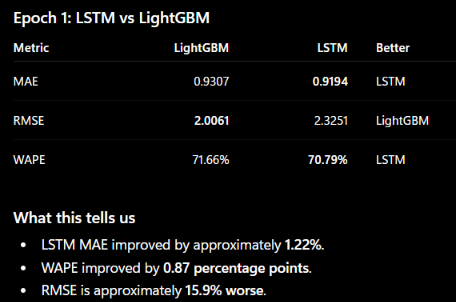

**Train Epoch 2**

In [ ]:
# Train second epoch on all 31 chunks

epoch2_result = train_full_epoch_resumable(
    epoch=2,
    resume_progress=None
)

assert epoch2_result["samples"] == EXPECTED_TRAIN_SAMPLES

# Record training results
training_history.append({
    "epoch": 2,
    "train_loss": epoch2_result["loss"],
    "train_samples": epoch2_result["samples"],
    "train_seconds": epoch2_result["seconds"]
})

# Save recovery checkpoint
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=2,
    progress=training_progress
)

print("\n========== EPOCH 2 COMPLETE ==========")
print(f"Training samples: {epoch2_result['samples']:,}")
print(f"Training loss: {epoch2_result['loss']:.6f}")
print(f"Training time: {epoch2_result['seconds']/60:.2f} minutes")
print(f"Throughput: {epoch2_result['samples_per_second']:.0f} samples/sec")
print(f"Current learning rate: {optimizer.param_groups[0]['lr']:.6f}")
print("\nEpoch 2 checkpoint saved.")


Training chunk 1/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 98212 samples/sec
Total completed: 1,502,000 samples

Training chunk 2/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97450 samples/sec
Total completed: 3,004,000 samples

Training chunk 3/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97246 samples/sec
Total completed: 4,506,000 samples

Training chunk 4/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 92427 samples/sec
Total completed: 6,008,000 samples

Training chunk 5/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 92879 samples/sec
Total completed: 7,510,000 samples

Training chunk 6/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 95572 samples/sec
Total completed: 9,012,000 samples

Training chunk 7/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 98287 samples/sec
Total completed: 10,514,000 samples

Training chunk 8/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 94636 samples/sec
Total comp

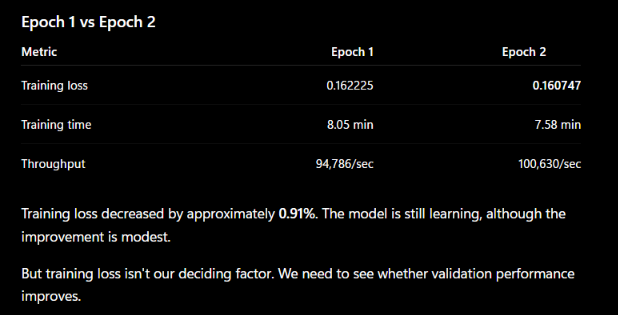

Full Validation after epoch 2

In [ ]:
# Validate on all 31 chunks
epoch2_validation = validate_one_epoch(
    files=parquet_files
)

# Verify complete validation coverage
assert epoch2_validation["samples"] == EXPECTED_VALID_SAMPLES

# Update history
epoch2_record = next(
    item for item in training_history
    if item["epoch"] == 2
)

epoch2_record.update({
    "validation_loss": epoch2_validation["loss"],
    "mae": epoch2_validation["mae"],
    "rmse": epoch2_validation["rmse"],
    "wape": epoch2_validation["wape"],
    "validation_samples": epoch2_validation["samples"],
    "validation_seconds": epoch2_validation["seconds"]
})

# Update learning-rate scheduler
scheduler.step(epoch2_validation["loss"])

# Save best model if validation improves
if epoch2_validation["loss"] < best_val_loss:

    best_val_loss = epoch2_validation["loss"]
    epochs_without_improvement = 0

    save_training_checkpoint(
        BEST_MODEL_PATH,
        epoch=2,
        progress=training_progress
    )

    print("\nNEW BEST MODEL SAVED!")

else:
    epochs_without_improvement += 1
    print("\nValidation loss did not improve.")

# Save latest checkpoint
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=2,
    progress=training_progress
)

# Results
print("\n========== EPOCH 2 VALIDATION ==========")
print(f"Validation samples: {epoch2_validation['samples']:,}")
print(f"Validation loss: {epoch2_validation['loss']:.6f}")
print(f"MAE: {epoch2_validation['mae']:.6f}")
print(f"RMSE: {epoch2_validation['rmse']:.6f}")
print(f"WAPE: {epoch2_validation['wape']:.2f}%")
print(f"Validation time: {epoch2_validation['seconds']/60:.2f} minutes")

print("\n========== EPOCH COMPARISON ==========")

for record in training_history:
    print(
        f"Epoch {record['epoch']} | "
        f"Train Loss: {record['train_loss']:.6f} | "
        f"Val Loss: {record['validation_loss']:.6f} | "
        f"MAE: {record['mae']:.6f} | "
        f"RMSE: {record['rmse']:.6f} | "
        f"WAPE: {record['wape']:.2f}%"
    )

print("\nCurrent learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs without improvement:", epochs_without_improvement)
print("Best validation loss:", best_val_loss)

Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31

NEW BEST MODEL SAVED!

========== EPOCH 2 VALIDATION ==========
Validation samples: 12,531,390
Validation loss: 0.215800
MAE: 0.889473
RMSE: 2.137365
WAPE: 68.49%
Validation time: 3.01 minutes

========== EPOCH COMPARISON ==========
Epoch 1 | Train Loss: 0.162225 | Val Loss: 0.220980 | MAE: 0.919404 | RMSE: 2.325085 | WAPE: 

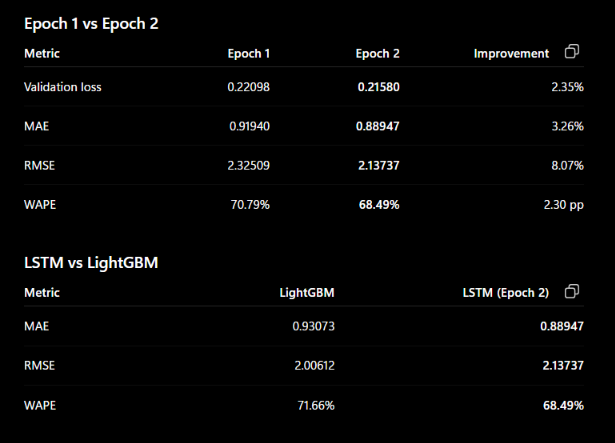

## **Train Epoch 3**

In [ ]:
epoch3_result = train_full_epoch_resumable(
    epoch=3,
    resume_progress=None
)

assert epoch3_result["samples"] == EXPECTED_TRAIN_SAMPLES

training_history.append({
    "epoch": 3,
    "train_loss": epoch3_result["loss"],
    "train_samples": epoch3_result["samples"],
    "train_seconds": epoch3_result["seconds"]
})

save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=3,
    progress=training_progress
)

print("\n========== EPOCH 3 COMPLETE ==========")
print(f"Training samples: {epoch3_result['samples']:,}")
print(f"Training loss: {epoch3_result['loss']:.6f}")
print(f"Training time: {epoch3_result['seconds']/60:.2f} minutes")
print(f"Throughput: {epoch3_result['samples_per_second']:.0f} samples/sec")
print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
print("\nEpoch 3 checkpoint saved.")


Training chunk 1/31
Processed chunk 1/1
Chunk samples: 735,980 | Speed: 102451 samples/sec
Total completed: 735,980 samples

Training chunk 2/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97672 samples/sec
Total completed: 2,237,980 samples

Training chunk 3/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 93907 samples/sec
Total completed: 3,739,980 samples

Training chunk 4/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 90719 samples/sec
Total completed: 5,241,980 samples

Training chunk 5/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 91899 samples/sec
Total completed: 6,743,980 samples

Training chunk 6/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 95422 samples/sec
Total completed: 8,245,980 samples

Training chunk 7/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97435 samples/sec
Total completed: 9,747,980 samples

Training chunk 8/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97304 samples/sec
Total complete

My target isn't to make LSTM win every metric artificially. It's to produce a reliable forecasting model and understand where it performs better or worse than LightGBM.

## **Full Validation after Epoch 3**

In [ ]:
epoch3_validation = validate_one_epoch(
    files=parquet_files
)

assert epoch3_validation["samples"] == EXPECTED_VALID_SAMPLES

epoch3_record = next(
    item for item in training_history
    if item["epoch"] == 3
)

epoch3_record.update({
    "validation_loss": epoch3_validation["loss"],
    "mae": epoch3_validation["mae"],
    "rmse": epoch3_validation["rmse"],
    "wape": epoch3_validation["wape"],
    "validation_samples": epoch3_validation["samples"],
    "validation_seconds": epoch3_validation["seconds"]
})

scheduler.step(epoch3_validation["loss"])

if epoch3_validation["loss"] < best_val_loss:

    best_val_loss = epoch3_validation["loss"]
    epochs_without_improvement = 0

    save_training_checkpoint(
        BEST_MODEL_PATH,
        epoch=3,
        progress=training_progress
    )

    print("NEW BEST MODEL SAVED!")

else:
    epochs_without_improvement += 1
    print("Validation loss did not improve.")

save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=3,
    progress=training_progress
)

print("\n========== EPOCH 3 VALIDATION ==========")
print(f"Validation loss: {epoch3_validation['loss']:.6f}")
print(f"MAE: {epoch3_validation['mae']:.6f}")
print(f"RMSE: {epoch3_validation['rmse']:.6f}")
print(f"WAPE: {epoch3_validation['wape']:.2f}%")
print(f"Validation time: {epoch3_validation['seconds']/60:.2f} minutes")

print("\n========== TRAINING HISTORY ==========")

for record in training_history:
    if "validation_loss" in record:
        print(
            f"Epoch {record['epoch']} | "
            f"Train Loss: {record['train_loss']:.6f} | "
            f"Val Loss: {record['validation_loss']:.6f} | "
            f"MAE: {record['mae']:.6f} | "
            f"RMSE: {record['rmse']:.6f} | "
            f"WAPE: {record['wape']:.2f}%"
        )

print("\nLearning rate:", optimizer.param_groups[0]["lr"])
print("Best validation loss:", best_val_loss)
print("Epochs without improvement:", epochs_without_improvement)

Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31
Validation loss did not improve.

========== EPOCH 3 VALIDATION ==========
Validation loss: 0.217135
MAE: 0.902027
RMSE: 2.315459
WAPE: 69.45%
Validation time: 3.03 minutes

========== TRAINING HISTORY ==========
Epoch 1 | Train Loss: 0.162225 | Val Loss: 0.220980 | MAE: 0.919404 | RMSE: 2.325085 | WAPE: 70.79%
Epoch 2 | Trai

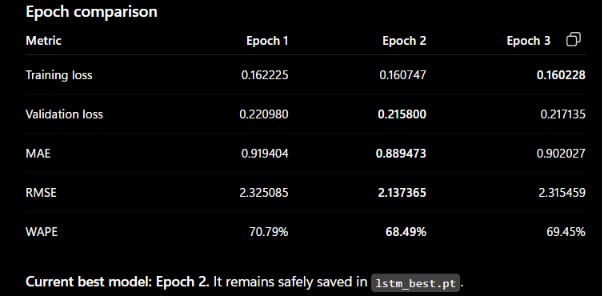

**Train Epoch 4** - let's try it

In [ ]:
epoch4_result = train_full_epoch_resumable(
    epoch=4,
    resume_progress=None
)

assert epoch4_result["samples"] == EXPECTED_TRAIN_SAMPLES

training_history.append({
    "epoch": 4,
    "train_loss": epoch4_result["loss"],
    "train_samples": epoch4_result["samples"],
    "train_seconds": epoch4_result["seconds"]
})

save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=4,
    progress=training_progress
)

print("\n========== EPOCH 4 COMPLETE ==========")
print(f"Training loss: {epoch4_result['loss']:.6f}")
print(f"Training time: {epoch4_result['seconds']/60:.2f} minutes")
print(f"Throughput: {epoch4_result['samples_per_second']:.0f} samples/sec")
print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
print("Recovery checkpoint saved.")


Training chunk 1/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 94262 samples/sec
Total completed: 1,502,000 samples

Training chunk 2/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 91718 samples/sec
Total completed: 3,004,000 samples

Training chunk 3/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 95015 samples/sec
Total completed: 4,506,000 samples

Training chunk 4/31
Processed chunk 1/1
Chunk samples: 735,980 | Speed: 103508 samples/sec
Total completed: 5,241,980 samples

Training chunk 5/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 98339 samples/sec
Total completed: 6,743,980 samples

Training chunk 6/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97899 samples/sec
Total completed: 8,245,980 samples

Training chunk 7/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 94895 samples/sec
Total completed: 9,747,980 samples

Training chunk 8/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 92132 samples/sec
Total comple

Full validate after epoch 4

In [ ]:
epoch4_validation = validate_one_epoch(
    files=parquet_files
)

assert epoch4_validation["samples"] == EXPECTED_VALID_SAMPLES

# Update epoch history
epoch4_record = next(
    item for item in training_history
    if item["epoch"] == 4
)

epoch4_record.update({
    "validation_loss": epoch4_validation["loss"],
    "mae": epoch4_validation["mae"],
    "rmse": epoch4_validation["rmse"],
    "wape": epoch4_validation["wape"],
    "validation_samples": epoch4_validation["samples"],
    "validation_seconds": epoch4_validation["seconds"]
})

# Update scheduler
scheduler.step(epoch4_validation["loss"])

# Save best model
if epoch4_validation["loss"] < best_val_loss:

    best_val_loss = epoch4_validation["loss"]
    epochs_without_improvement = 0

    save_training_checkpoint(
        BEST_MODEL_PATH,
        epoch=4,
        progress=training_progress
    )

    print("NEW BEST MODEL SAVED!")

else:
    epochs_without_improvement += 1
    print("Validation loss did not improve.")

# Save recovery checkpoint
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=4,
    progress=training_progress
)

print("\n========== EPOCH 4 VALIDATION ==========")

print(f"Validation loss: {epoch4_validation['loss']:.6f}")
print(f"MAE: {epoch4_validation['mae']:.6f}")
print(f"RMSE: {epoch4_validation['rmse']:.6f}")
print(f"WAPE: {epoch4_validation['wape']:.2f}%")

print(f"Validation time: {epoch4_validation['seconds']/60:.2f} minutes")

print("\n========== TRAINING HISTORY ==========")

for record in training_history:

    if "validation_loss" in record:

        print(
            f"Epoch {record['epoch']} | "
            f"Train: {record['train_loss']:.6f} | "
            f"Val: {record['validation_loss']:.6f} | "
            f"MAE: {record['mae']:.6f} | "
            f"RMSE: {record['rmse']:.6f} | "
            f"WAPE: {record['wape']:.2f}%"
        )

print("\nLearning rate:", optimizer.param_groups[0]["lr"])
print("Best validation loss:", best_val_loss)
print("Epochs without improvement:", epochs_without_improvement)

Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31
Validation loss did not improve.

========== EPOCH 4 VALIDATION ==========
Validation loss: 0.217465
MAE: 0.893776
RMSE: 2.162783
WAPE: 68.82%
Validation time: 3.04 minutes

========== TRAINING HISTORY ==========
Epoch 1 | Train: 0.162225 | Val: 0.220980 | MAE: 0.919404 | RMSE: 2.325085 | WAPE: 70.79%
Epoch 2 | Train: 0.16074

In [ ]:
epoch5_result = train_full_epoch_resumable(
    epoch=5,
    resume_progress=None
)

assert epoch5_result["samples"] == EXPECTED_TRAIN_SAMPLES

training_history.append({
    "epoch": 5,
    "train_loss": epoch5_result["loss"],
    "train_samples": epoch5_result["samples"],
    "train_seconds": epoch5_result["seconds"]
})

save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=5,
    progress=training_progress
)

print("\n========== EPOCH 5 COMPLETE ==========")
print(f"Training loss: {epoch5_result['loss']:.6f}")
print(f"Training time: {epoch5_result['seconds']/60:.2f} minutes")
print(f"Throughput: {epoch5_result['samples_per_second']:.0f} samples/sec")
print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
print("Recovery checkpoint saved.")


Training chunk 1/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 69997 samples/sec
Total completed: 1,502,000 samples

Training chunk 2/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97549 samples/sec
Total completed: 3,004,000 samples

Training chunk 3/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 96888 samples/sec
Total completed: 4,506,000 samples

Training chunk 4/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 96768 samples/sec
Total completed: 6,008,000 samples

Training chunk 5/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 97143 samples/sec
Total completed: 7,510,000 samples

Training chunk 6/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 77385 samples/sec
Total completed: 9,012,000 samples

Training chunk 7/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 71535 samples/sec
Total completed: 10,514,000 samples

Training chunk 8/31
Processed chunk 1/1
Chunk samples: 1,502,000 | Speed: 96624 samples/sec
Total comp

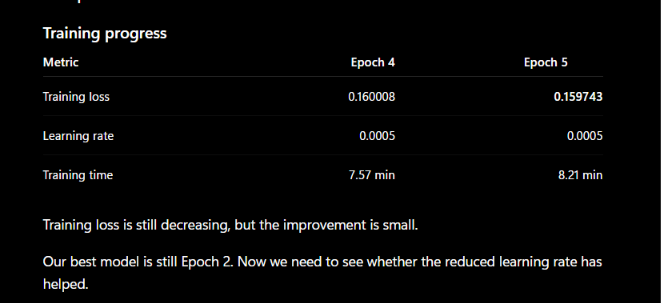

### Full Validation after epoch 5

In [ ]:
epoch5_validation = validate_one_epoch(
    files=parquet_files
)

assert epoch5_validation["samples"] == EXPECTED_VALID_SAMPLES

# Update history
epoch5_record = next(
    item for item in training_history
    if item["epoch"] == 5
)

epoch5_record.update({
    "validation_loss": epoch5_validation["loss"],
    "mae": epoch5_validation["mae"],
    "rmse": epoch5_validation["rmse"],
    "wape": epoch5_validation["wape"],
    "validation_samples": epoch5_validation["samples"],
    "validation_seconds": epoch5_validation["seconds"]
})

# Scheduler update
scheduler.step(epoch5_validation["loss"])

# Check whether this is our best model
if epoch5_validation["loss"] < best_val_loss:

    best_val_loss = epoch5_validation["loss"]
    epochs_without_improvement = 0

    save_training_checkpoint(
        BEST_MODEL_PATH,
        epoch=5,
        progress=training_progress
    )

    print("NEW BEST MODEL SAVED!")

else:
    epochs_without_improvement += 1
    print("Validation loss did not improve.")

# Save latest checkpoint
save_training_checkpoint(
    LAST_CHECKPOINT_PATH,
    epoch=5,
    progress=training_progress
)

print("\n========== EPOCH 5 VALIDATION ==========")

print(f"Validation loss: {epoch5_validation['loss']:.6f}")
print(f"MAE: {epoch5_validation['mae']:.6f}")
print(f"RMSE: {epoch5_validation['rmse']:.6f}")
print(f"WAPE: {epoch5_validation['wape']:.2f}%")

print("\n========== COMPLETE TRAINING HISTORY ==========")

for record in training_history:

    if "validation_loss" in record:

        print(
            f"Epoch {record['epoch']} | "
            f"Train: {record['train_loss']:.6f} | "
            f"Val: {record['validation_loss']:.6f} | "
            f"MAE: {record['mae']:.6f} | "
            f"RMSE: {record['rmse']:.6f} | "
            f"WAPE: {record['wape']:.2f}%"
        )

print("\nLearning rate:", optimizer.param_groups[0]["lr"])
print("Best validation loss:", best_val_loss)
print("Epochs without improvement:", epochs_without_improvement)

Processed chunk 1/31
Processed chunk 2/31
Processed chunk 3/31
Processed chunk 4/31
Processed chunk 5/31
Processed chunk 6/31
Processed chunk 7/31
Processed chunk 8/31
Processed chunk 9/31
Processed chunk 10/31
Processed chunk 11/31
Processed chunk 12/31
Processed chunk 13/31
Processed chunk 14/31
Processed chunk 15/31
Processed chunk 16/31
Processed chunk 17/31
Processed chunk 18/31
Processed chunk 19/31
Processed chunk 20/31
Processed chunk 21/31
Processed chunk 22/31
Processed chunk 23/31
Processed chunk 24/31
Processed chunk 25/31
Processed chunk 26/31
Processed chunk 27/31
Processed chunk 28/31
Processed chunk 29/31
Processed chunk 30/31
Processed chunk 31/31
Validation loss did not improve.

========== EPOCH 5 VALIDATION ==========
Validation loss: 0.216647
MAE: 0.887903
RMSE: 2.149717
WAPE: 68.37%

========== COMPLETE TRAINING HISTORY ==========
Epoch 1 | Train: 0.162225 | Val: 0.220980 | MAE: 0.919404 | RMSE: 2.325085 | WAPE: 70.79%
Epoch 2 | Train: 0.160747 | Val: 0.215800 | M

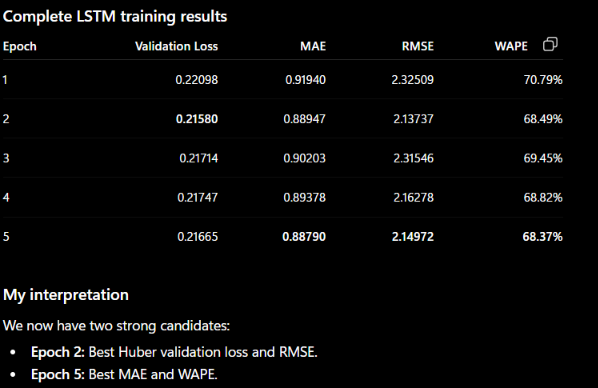

# We'll select LSTM Epoch 5 as our final model

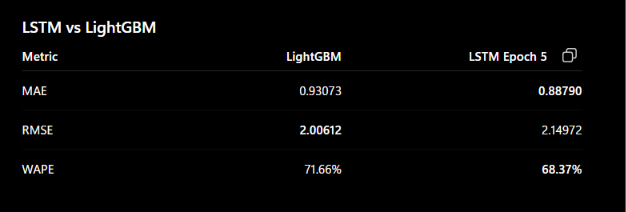

### Preserve our best WAPE model  

In [ ]:
# Save Epoch 5 as the best WAPE candidate
BEST_WAPE_PATH = os.path.join(
    MODEL_DIR,
    "lstm_best_wape.pt"
)

save_training_checkpoint(
    BEST_WAPE_PATH,
    epoch=5,
    progress=training_progress
)

# Save comparison summary
import json

model_comparison = {
    "lightgbm": {
        "mae": 0.930733,
        "rmse": 2.006124,
        "wape": 71.662936
    },
    "lstm_epoch_2": {
        "validation_loss": 0.2157997908685804,
        "mae": 0.889473,
        "rmse": 2.137365,
        "wape": 68.49
    },
    "lstm_epoch_5": {
        "validation_loss": 0.216647,
        "mae": 0.887903,
        "rmse": 2.149717,
        "wape": 68.37
    }
}

comparison_path = os.path.join(
    MODEL_DIR,
    "model_comparison.json"
)

with open(comparison_path, "w") as f:
    json.dump(model_comparison, f, indent=4)

print("Epoch 5 WAPE candidate saved:", BEST_WAPE_PATH)
print("Epoch 2 best-loss checkpoint preserved:", BEST_MODEL_PATH)
print("Comparison report saved:", comparison_path)

Epoch 5 WAPE candidate saved: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best_wape.pt
Epoch 2 best-loss checkpoint preserved: /content/drive/MyDrive/Retail-Demand-Forecasting/models/lstm_best.pt
Comparison report saved: /content/drive/MyDrive/Retail-Demand-Forecasting/models/model_comparison.json


### Save Epoch 5 as the final model

In [ ]:
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "retail_demand_lstm_final.pt"
)

# Save the selected Epoch 5 model
save_training_checkpoint(
    FINAL_MODEL_PATH,
    epoch=5,
    progress=training_progress
)

# Verify checkpoint
assert os.path.exists(FINAL_MODEL_PATH)

checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["epoch"] == 5

print("FINAL MODEL SAVED SUCCESSFULLY")
print("Selected epoch:", checkpoint["epoch"])
print("Model path:", FINAL_MODEL_PATH)
print("File size:", round(os.path.getsize(FINAL_MODEL_PATH) / (1024**2), 2), "MB")

FINAL MODEL SAVED SUCCESSFULLY
Selected epoch: 5
Model path: /content/drive/MyDrive/Retail-Demand-Forecasting/models/retail_demand_lstm_final.pt
File size: 2.51 MB
